In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from scipy.stats import permutation_test

In [2]:
df = sns.load_dataset("mpg").dropna()

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df["target"] = (df["mpg"] > df["mpg"].median()).astype(int)

X = df.drop(columns=["mpg", "target", "name"])

X = pd.get_dummies(X, columns=["origin"], drop_first=True)

y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier()
}

In [5]:
results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    predictions[name] = (y_pred, y_proba)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")
    auc = roc_auc_score(y_test, y_proba[:, 1])

    results.append([name, acc, f1, auc])

    print("\n====================", name, "====================")
    print("Accuracy:", acc)
    print("F1:", f1)
    print("AUC:", auc)


==================== Logistic Regression ====================
Accuracy: 0.9113924050632911
F1: 0.9113071644717214
AUC: 0.9769230769230769

==================== Decision Tree ====================
Accuracy: 0.9113924050632911
F1: 0.9111077220273498
AUC: 0.9121794871794872

==================== Random Forest ====================
Accuracy: 0.9240506329113924
F1: 0.9239043889439561
AUC: 0.9746794871794872

==================== KNN ====================
Accuracy: 0.8734177215189873
F1: 0.8734177215189873
AUC: 0.9403846153846154


In [6]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1", "AUC"])
results_df

,Model,Accuracy,F1,AUC
0,Logistic Regression,0.911392,0.911307,0.976923
1,Decision Tree,0.911392,0.911108,0.912179
2,Random Forest,0.924051,0.923904,0.974679
3,KNN,0.873418,0.873418,0.940385


In [7]:
def bootstrap_metric(y_true, y_pred, metric_fn, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    n = len(y_true)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    for _ in range(n_boot):
        idx = rng.integers(0, n, n)

        yt = y_true[idx]
        yp = y_pred[idx]

        scores.append(metric_fn(yt, yp))

    scores = np.array(scores)

    return np.mean(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

In [8]:
boot_results = []

for name in models.keys():

    y_pred, y_proba = predictions[name]

    acc = bootstrap_metric(y_test, y_pred,
        lambda yt, yp: accuracy_score(yt, yp))

    f1 = bootstrap_metric(y_test, y_pred,
        lambda yt, yp: f1_score(yt, yp, average="weighted"))

    auc = bootstrap_metric(y_test, y_proba, lambda yt, yp: roc_auc_score(yt, yp[:, 1]))

    boot_results.append([name, acc, f1, auc])

In [9]:
boot_df = pd.DataFrame(
    boot_results,
    columns=["Model", "Accuracy_CI", "F1_CI", "AUC_CI"]
)

boot_df

,Model,Accuracy_CI,F1_CI,AUC_CI
0,Logistic Regression,"(0.9099556962025315, 0.8354430379746836, 0.974...","(0.9098896723424595, 0.8359153114427377, 0.974...","(0.9761831678055821, 0.9461538461538462, 0.996..."
1,Decision Tree,"(0.9108670886075947, 0.8481012658227848, 0.962...","(0.9105664862230877, 0.8450524340156207, 0.962...","(0.9119788963630082, 0.8486929165605637, 0.964..."
2,Random Forest,"(0.9249810126582276, 0.8607594936708861, 0.974...","(0.9248323941750487, 0.8598170115974255, 0.974...","(0.9747934931760549, 0.9398263474272689, 0.998..."
3,KNN,"(0.874525316455696, 0.7974683544303798, 0.9367...","(0.8745459236143254, 0.7974683544303798, 0.937...","(0.9406213536615043, 0.8854568854568855, 0.982..."


## Confidence Interval Interpretation

Yes, some of the confidence intervals for Accuracy, F1-score, and ROC-AUC overlap between the models.

This means that although there are differences in the average performance of the models, these differences are not always statistically strong enough to conclude that one model is clearly better than the others.

When confidence intervals overlap, it suggests that the observed performance differences may be due to random variation in the test data rather than a true difference in model quality.

However, if certain models show only minimal or no overlap in their confidence intervals (especially for ROC-AUC or F1-score), this indicates that those models may be meaningfully different in performance and one could be preferred over the other.

Overall, the overlap of confidence intervals highlights the importance of considering uncertainty rather than relying only on single point estimates like accuracy.

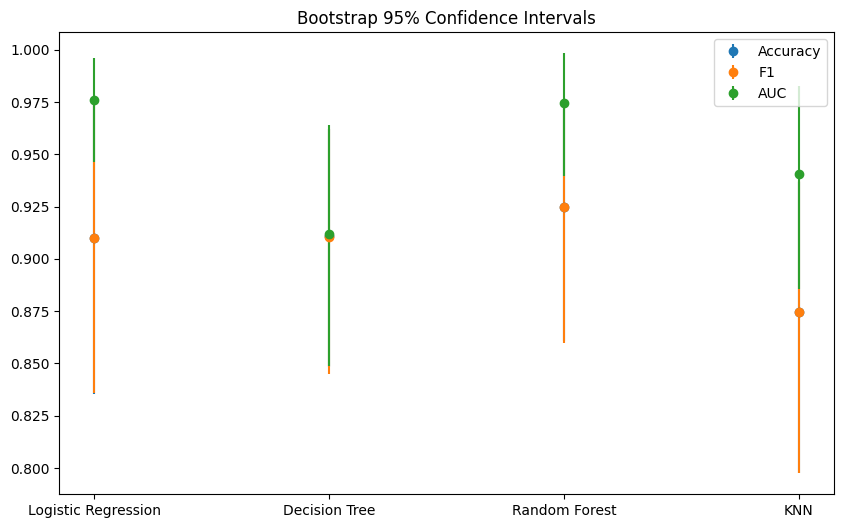

In [10]:
labels = [r[0] for r in boot_results]

plt.figure(figsize=(10,6))

metrics = ["Accuracy", "F1", "AUC"]

for i in range(3):

    means = [r[i+1][0] for r in boot_results]
    lower = [r[i+1][1] for r in boot_results]
    upper = [r[i+1][2] for r in boot_results]

    err = np.array([
        np.array(means) - np.array(lower),
        np.array(upper) - np.array(means)
    ])

    plt.errorbar(labels, means, yerr=err, fmt='o', label=metrics[i])

plt.title("Bootstrap 95% Confidence Intervals")
plt.legend()
plt.show()

In [11]:
model_A = "Random Forest"
model_B = "Logistic Regression"

yA = predictions[model_A][0]
yB = predictions[model_B][0]

result = permutation_test(
    (yA, yB),
    statistic=lambda a, b: np.mean(a == np.array(y_test)) - np.mean(b == np.array(y_test)),
    n_resamples=5000,
    alternative="two-sided"
)

print("Accuracy RF:", np.mean(yA == y_test))
print("Accuracy LogReg:", np.mean(yB == y_test))
print("Difference:", np.mean(yA == y_test) - np.mean(yB == y_test))
print("p-value:", result.pvalue)

Accuracy RF: 0.9240506329113924
Accuracy LogReg: 0.9113924050632911
Difference: 0.012658227848101333
p-value: 1.0


In [12]:
rng = np.random.default_rng(42)

diffs = []

for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))

    yt = np.array(y_test)[idx]

    f1_A = f1_score(yt, yA[idx], average="weighted")
    f1_B = f1_score(yt, yB[idx], average="weighted")

    diffs.append(f1_A - f1_B)

obs = f1_score(y_test, yA, average="weighted") - f1_score(y_test, yB, average="weighted")

p_value = np.mean(np.abs(diffs) >= abs(obs))

print("F1 difference:", obs)
print("p-value:", p_value)

F1 difference: 0.012597224472234658
p-value: 0.78
